In [1]:
import pandas as pd
import boto3
import seaborn as sns

bucket = "insurance-pricing-model-akshayaa"  # S3 bucket name

In [2]:
freq = pd.read_csv(f"s3://{bucket}/freMTPL2freq.csv")
sev = pd.read_csv(f"s3://{bucket}/freMTPL2sev.csv")

print("freq shape:", freq.shape)
print("sev shape:", sev.shape)

C:\Users\prish\OneDrive\Desktop\Insurance Project\Insurance-Underwriting-Pricing-Model\venv\lib\site-packages\fsspec\registry.py:305: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)


freq shape: (678013, 12)
sev shape: (26639, 2)


### Capture this to DataFrame :)

In [3]:
df_freq=pd.DataFrame(freq)
df_sev=pd.DataFrame(sev)
print(df_freq.head())

   IDpol  ClaimNb  Exposure Area  VehPower  VehAge  DrivAge  BonusMalus  \
0    1.0        1      0.10    D         5       0       55          50   
1    3.0        1      0.77    D         5       0       55          50   
2    5.0        1      0.75    B         6       2       52          50   
3   10.0        1      0.09    B         7       0       46          50   
4   11.0        1      0.84    B         7       0       46          50   

  VehBrand   VehGas  Density Region  
0      B12  Regular     1217    R82  
1      B12  Regular     1217    R82  
2      B12   Diesel       54    R22  
3      B12   Diesel       76    R72  
4      B12   Diesel       76    R72  


### Convert IDs of both datasets to int

In [4]:
df_freq['IDpol'] = df_freq['IDpol'].astype(int)
print(df_freq.head())

   IDpol  ClaimNb  Exposure Area  VehPower  VehAge  DrivAge  BonusMalus  \
0      1        1      0.10    D         5       0       55          50   
1      3        1      0.77    D         5       0       55          50   
2      5        1      0.75    B         6       2       52          50   
3     10        1      0.09    B         7       0       46          50   
4     11        1      0.84    B         7       0       46          50   

  VehBrand   VehGas  Density Region  
0      B12  Regular     1217    R82  
1      B12  Regular     1217    R82  
2      B12   Diesel       54    R22  
3      B12   Diesel       76    R72  
4      B12   Diesel       76    R72  


In [5]:
df_sev['IDpol'] = df_sev['IDpol'].astype(int)
print(df_sev.head())

     IDpol  ClaimAmount
0     1552       995.20
1  1010996      1128.12
2  4024277      1851.11
3  4007252      1204.00
4  4046424      1204.00


In [6]:
print("Duplicate IDpol in df_freq:", df_freq['IDpol'].duplicated().sum())

Duplicate IDpol in df_freq: 0


In [7]:
print("Duplicate IDpol in df_sev:", df_sev['IDpol'].duplicated().sum())

Duplicate IDpol in df_sev: 1689


##### Note: Duplicate entries found in severity data: this means that one person/policy account can, and infact will have multiple claims. 

In [8]:
df_freq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  int64  
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   Area        678013 non-null  object 
 4   VehPower    678013 non-null  int64  
 5   VehAge      678013 non-null  int64  
 6   DrivAge     678013 non-null  int64  
 7   BonusMalus  678013 non-null  int64  
 8   VehBrand    678013 non-null  object 
 9   VehGas      678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(1), int64(7), object(4)
memory usage: 62.1+ MB


In [9]:
df_sev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol        26639 non-null  int64  
 1   ClaimAmount  26639 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 416.4 KB


##### 0 missing values- which is a good thing!

### Plotting target variable (ClaimNB) distribution

In [10]:
import matplotlib.pyplot as plt

claim_counts = df_freq['ClaimNb'].value_counts().sort_index()
print(claim_counts)

ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64


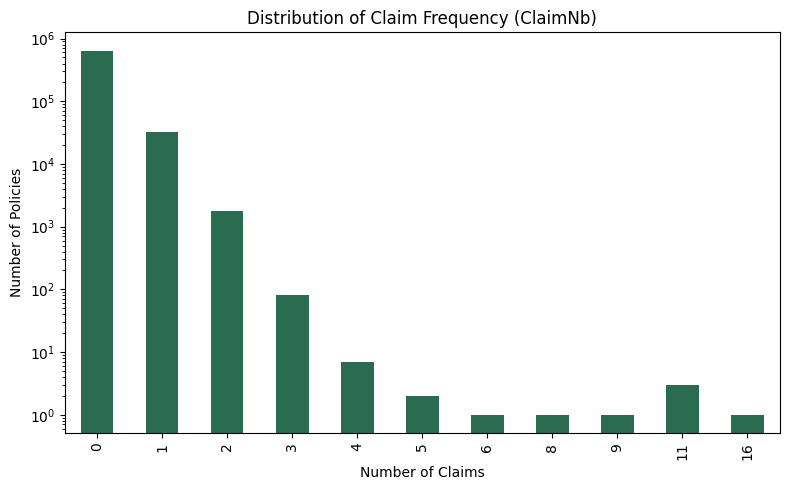

In [11]:
plt.figure(figsize=(8,5))
claim_counts.plot(kind='bar', color='#2a6b52')
plt.title('Distribution of Claim Frequency (ClaimNb)')
plt.xlabel('Number of Claims')
plt.ylabel('Number of Policies')
plt.yscale('log')
plt.tight_layout()
plt.show()

##### Note: 90% of the policy has zero claims, ~ 4.8% have 1 claim, 0.26% have 2 claims, and it drops off fast from there. This is an example of a non-normal distribution, meaning most of the population have not filed any claims, but some of them do file, roughly more than once or twice or thrice. Hence, we can use GLM as a baseline model that captures non-linear relationships.  


### For claims that are filled more than 5, we investigate the datasets further

In [12]:
df_freq[df_freq['ClaimNb'] >= 6]

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
6539,19471,11,1.00,A,5,6,65,50,B2,Diesel,13,R24
304484,2216294,6,0.33,D,4,12,52,50,B1,Regular,824,R91
320764,2239279,8,0.41,D,4,12,52,50,B1,Regular,824,R91
321248,2241683,16,0.33,D,4,12,52,50,B1,Regular,824,R91
321512,2248174,9,0.08,D,4,12,52,50,B1,Regular,824,R91
487268,3253234,11,0.08,D,4,13,53,50,B1,Regular,824,R91
488270,3254353,11,0.07,D,4,13,53,50,B1,Regular,824,R91


In [13]:
outliers = df_freq[df_freq['ClaimNb'] >= 6].copy()
outliers['freq_rate'] = outliers['ClaimNb'] / outliers['Exposure']
print(outliers[['IDpol','ClaimNb','Exposure']].assign(freq_rate=outliers['freq_rate']).sort_values('freq_rate', ascending=False))

          IDpol  ClaimNb  Exposure   freq_rate
488270  3254353       11      0.07  157.142857
487268  3253234       11      0.08  137.500000
321512  2248174        9      0.08  112.500000
321248  2241683       16      0.33   48.484848
320764  2239279        8      0.41   19.512195
304484  2216294        6      0.33   18.181818
6539      19471       11      1.00   11.000000


##### Above, for the frequency rate of number of claims for more than 5 has absurd values like 137- meaning it is not possible for a policy to file a claim more than 10 times in a month i.e. more than 100 times a year. So, we cap all these values to 5. 

In [14]:
df_freq['ClaimNb'] = df_freq['ClaimNb'].clip(upper=5)

In [15]:
print(df_freq['ClaimNb'].value_counts().sort_index())

ClaimNb
0    643953
1     32178
2      1784
3        82
4         7
5         9
Name: count, dtype: int64


#### Exploring our first feature: Exposure (period of coverage)

In [16]:
print((df_freq['Exposure']>1.0).sum())

1224


In [17]:
print((df_freq['Exposure']<0.5).sum())

341617


#### Exposure represents the fraction of a policy year a vehicle was insured, and can never exceed 1.0 by definition. Records with Exposure > 1.0 (0.18% of the portfolio) violate this constraint and were removed below rather than adjusted. 

In [18]:
df_freq=df_freq[df_freq['Exposure']<=1.0]
print(df_freq.shape)

(676789, 12)


##### Note on Exposure and ClaimNB: A policy with ClaimNb = 1 and Exposure = 0.08 (about 1 month) is a very different risk than a policy with ClaimNb = 1 and Exposure = 1.0 (a full year).

##### Policy A: 1 claim in 1 month → annualized rate ≈ 12 claims/year (extreme)
##### Policy B: 1 claim in 12 months → annualized rate = 1 claim/year (normal)

##### Same ClaimNB, but different total frequency in a year. Hence, our goal is to model ClaimNb / Exposure and use log(Exposure) as an offset. 

### Categorical Data Visualization

<Axes: xlabel='Area'>

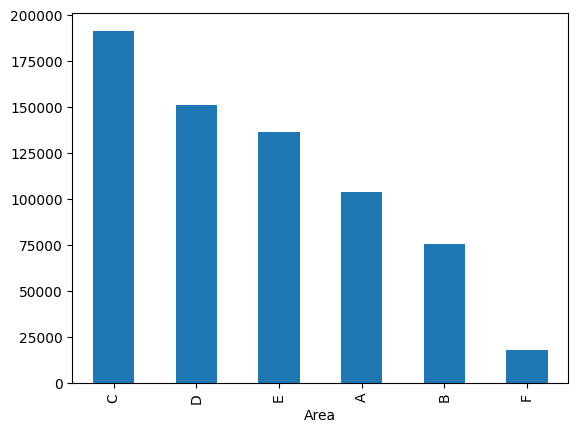

In [19]:
df_freq['Area'].value_counts().plot(kind='bar')

<Axes: xlabel='VehBrand'>

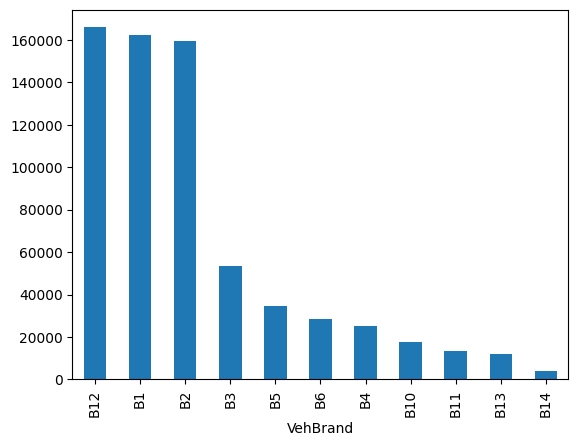

In [20]:
df_freq['VehBrand'].value_counts().plot(kind='bar')

C:\Users\prish\AppData\Local\Temp\ipykernel_8300\3554823733.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grouped = df_freq.groupby(['VehBrand', 'VehGas']).apply(


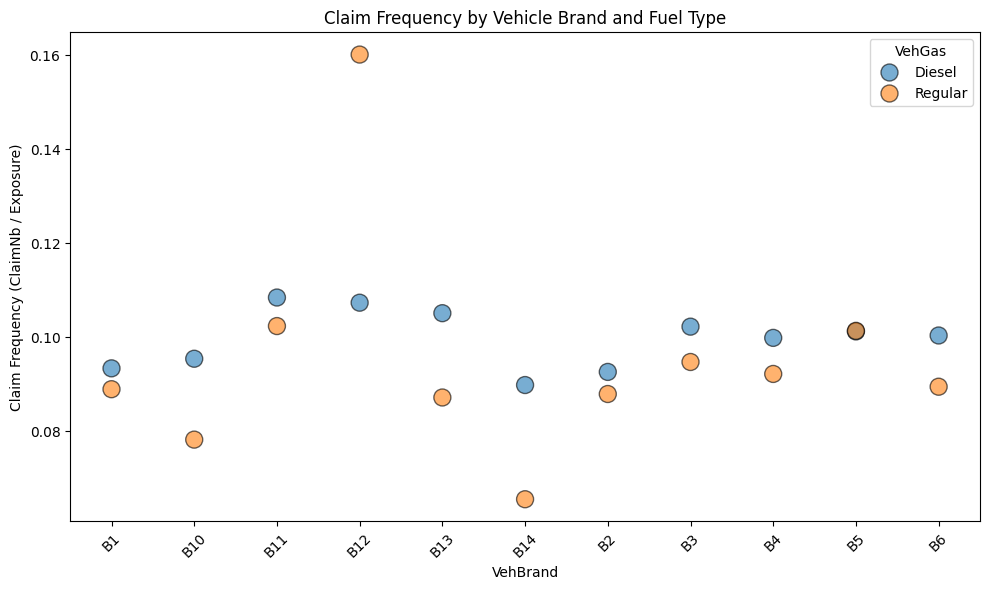

In [21]:
# Step 1: Compute claim frequency (ClaimNb sum / Exposure sum) grouped by VehBrand and VehGas
grouped = df_freq.groupby(['VehBrand', 'VehGas']).apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
).reset_index(name='claim_frequency')

# Step 2: Plot as a scatter plot, colored by VehGas
plt.figure(figsize=(10,6))
sns.scatterplot(data=grouped, x='VehBrand', y='claim_frequency', hue='VehGas', s=150, alpha=0.6, edgecolor='black')
plt.title('Claim Frequency by Vehicle Brand and Fuel Type')
plt.xlabel('VehBrand')
plt.ylabel('Claim Frequency (ClaimNb / Exposure)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
print(grouped[grouped['VehBrand'] == 'B5'])

   VehBrand   VehGas  claim_frequency
18       B5   Diesel         0.101227
19       B5  Regular         0.101350


##### Above, we observe:
##### 1. For B12 vehicle type that runs on petrol (regular gas), there is a striking outlier (valued at 0.16) worth investigating further. 
##### 2. For B5 vehicle type, the claim frequency for both gas types are almost the same, hence they overlap on the scatterplot. 
##### 3. B14 vehicle type has the lowest claim frequency so far. 

#### Investing B12 further

In [23]:
b12_regular = df_freq[(df_freq['VehBrand'] == 'B12') & (df_freq['VehGas'] == 'Regular')]

print("Number of B12-Regular policies:", len(b12_regular))
print("Total ClaimNb:", b12_regular['ClaimNb'].sum())
print("Total Exposure:", b12_regular['Exposure'].sum())
print("Computed frequency:", b12_regular['ClaimNb'].sum() / b12_regular['Exposure'].sum())

Number of B12-Regular policies: 90609
Total ClaimNb: 5793
Total Exposure: 36182.146263832
Computed frequency: 0.1601065884195691


In [24]:
print(b12_regular['ClaimNb'].value_counts().sort_index())

ClaimNb
0    85188
1     5072
2      330
3       15
4        4
Name: count, dtype: int64


In [25]:
compare_cols = ['DrivAge', 'BonusMalus', 'VehPower', 'VehAge', 'Density']
print(df_freq[df_freq['VehBrand']=='B12'].groupby('VehGas')[compare_cols].mean())

           DrivAge  BonusMalus  VehPower    VehAge      Density
VehGas                                                         
Diesel   46.682561    57.90568  7.372037  2.259177  1993.070630
Regular  48.102175    59.56693  6.426359  2.869417  3276.264289


In [26]:
b12_regular_profile = df_freq[(df_freq['VehBrand']=='B12') & (df_freq['VehGas']=='Regular')][compare_cols].mean()
all_regular_profile = df_freq[df_freq['VehGas']=='Regular'][compare_cols].mean()

comparison = pd.DataFrame({'B12_Regular': b12_regular_profile, 'All_Regular_Avg': all_regular_profile})
print(comparison)

            B12_Regular  All_Regular_Avg
DrivAge       48.102175        46.493024
BonusMalus    59.566930        60.247844
VehPower       6.426359         6.334641
VehAge         2.869417         7.747319
Density     3276.264289      2176.278616


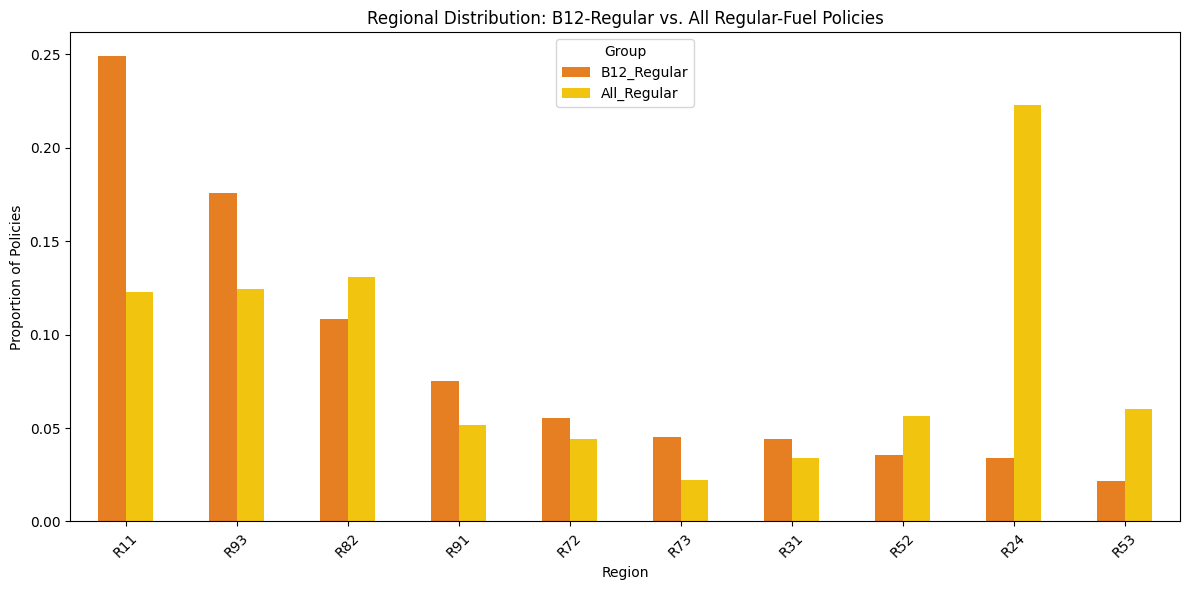

In [27]:
b12_regular_region = df_freq[(df_freq['VehBrand']=='B12') & (df_freq['VehGas']=='Regular')]['Region'].value_counts(normalize=True)
all_regular_region = df_freq[df_freq['VehGas']=='Regular']['Region'].value_counts(normalize=True)

region_compare = pd.DataFrame({
    'B12_Regular': b12_regular_region,
    'All_Regular': all_regular_region
}).fillna(0).sort_values('B12_Regular', ascending=False)

region_compare.head(10).plot(kind='bar', figsize=(12,6), color=['#e67e22', '#f1c40f'])
plt.title('Regional Distribution: B12-Regular vs. All Regular-Fuel Policies')
plt.xlabel('Region')
plt.ylabel('Proportion of Policies')
plt.xticks(rotation=45)
plt.legend(title='Group')
plt.tight_layout()
plt.show()

#### Above, we observe: 
#### 1. B12-Regular (~25%) is roughly 2x the All-Regular baseline (~12%) in region R11. This demonstrates geographic concentration effects. 

<Axes: xlabel='VehGas'>

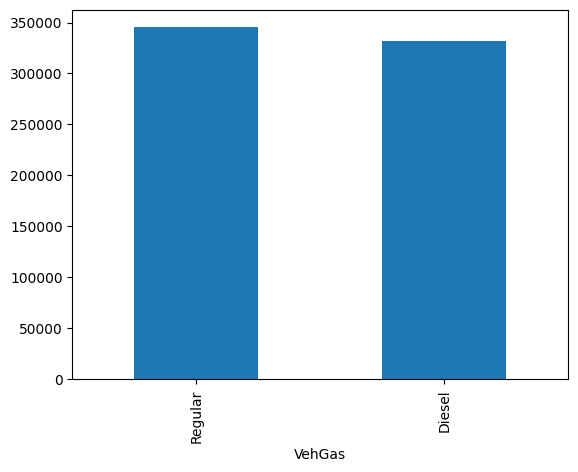

In [28]:
df_freq['VehGas'].value_counts().plot(kind='bar')

### Numerical Data Visualization

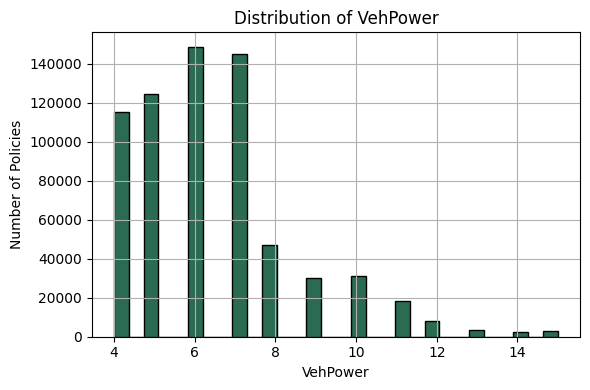

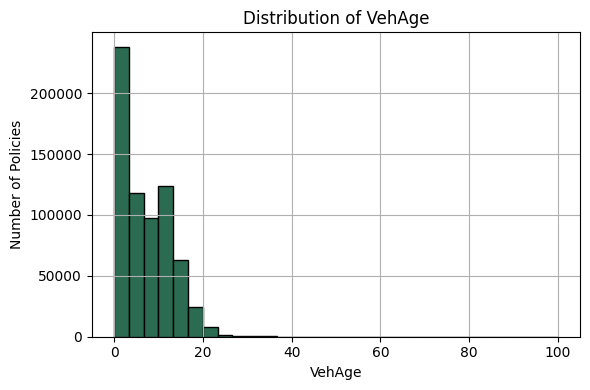

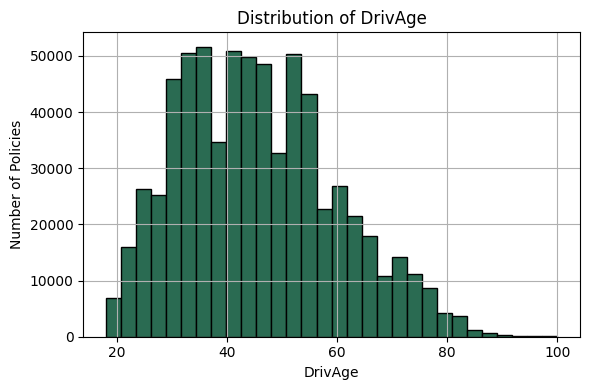

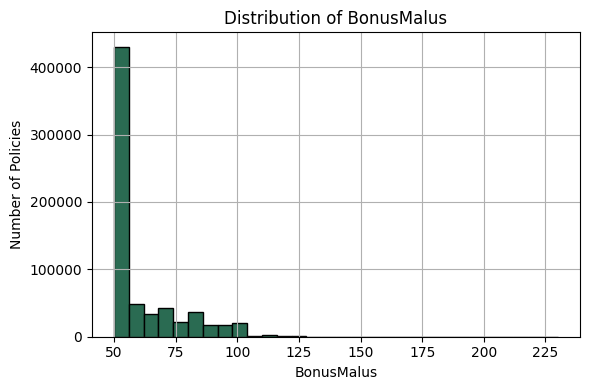

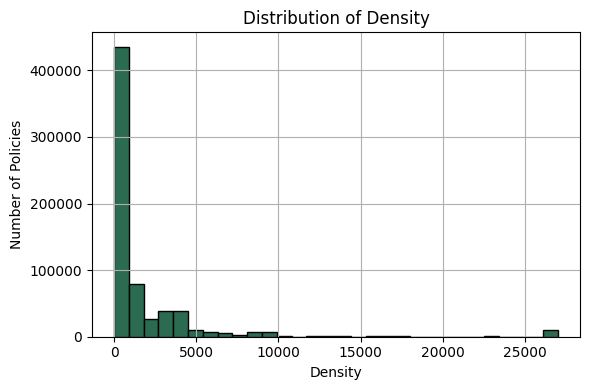

In [29]:
for col in ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Density']:
    plt.figure(figsize=(6,4))
    df_freq[col].hist(bins=30, color='#2a6b52', edgecolor='black')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Policies')
    plt.tight_layout()
    plt.show()

#### Zooming in Vehicle Age

In [51]:
print((df_freq['VehAge'] > 30).sum())
print(df_freq[df_freq['VehAge'] > 30]['VehAge'].describe())

1113
count    1113.000000
mean       39.318059
std        15.151614
min        31.000000
25%        32.000000
50%        34.000000
75%        38.000000
max       100.000000
Name: VehAge, dtype: float64


In [52]:
df_freq[df_freq['VehAge'] > 30][['IDpol', 'VehAge', 'DrivAge', 'ClaimNb', 'Exposure']].head(20)

,IDpol,VehAge,DrivAge,ClaimNb,Exposure
5530,17554,37,62,2,1.00
7068,20490,33,78,1,1.00
7767,21836,42,75,1,0.24
8048,22360,31,86,1,1.00
9086,24404,33,46,1,1.00
9114,24458,33,53,1,0.08
9115,24459,33,53,1,0.21
10358,26662,32,32,0,0.28
10371,26685,34,27,0,0.08
10372,26686,34,27,0,0.75


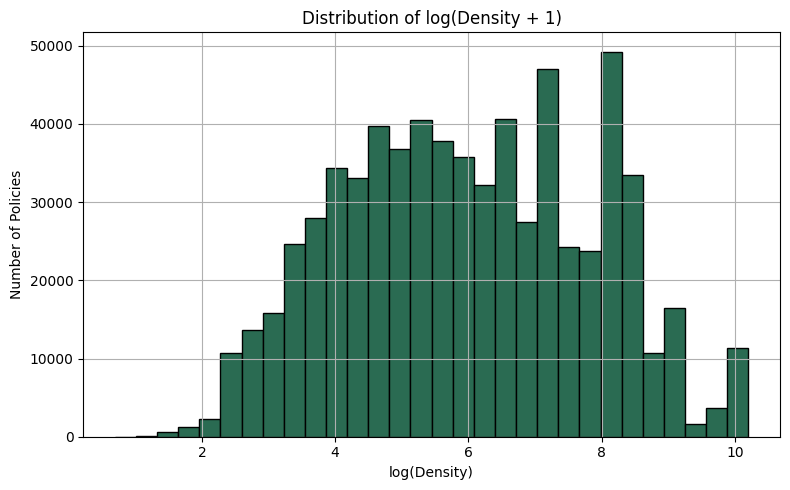

In [30]:
import numpy as np
plt.figure(figsize=(8,5))
np.log1p(df_freq['Density']).hist(bins=30, color='#2a6b52', edgecolor='black')
plt.title('Distribution of log(Density + 1)')
plt.xlabel('log(Density)')
plt.ylabel('Number of Policies')
plt.tight_layout()
plt.show()

C:\Users\prish\AppData\Local\Temp\ipykernel_8300\474860580.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_freq.groupby(bonus_bins)['ClaimNb'].mean().plot(kind='bar', figsize=(10,5), color='#2a6b52')


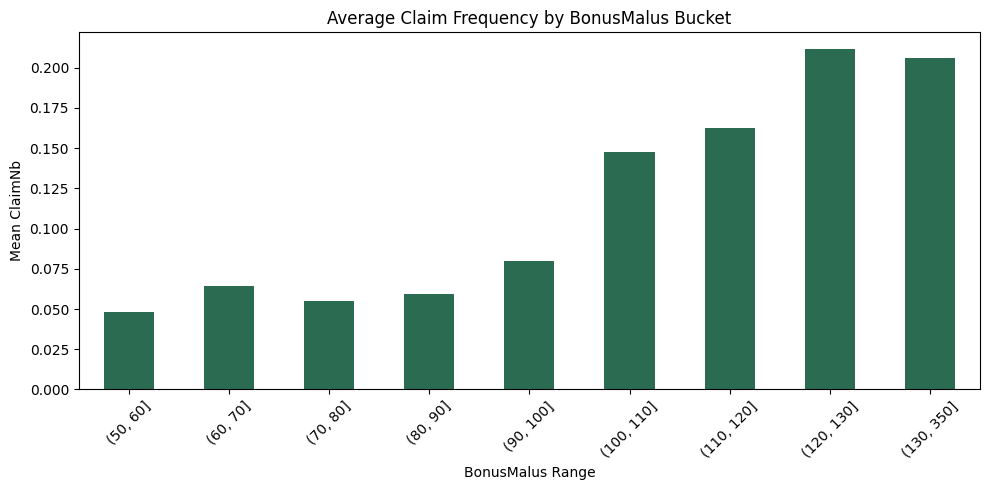

In [31]:
bonus_bins = pd.cut(df_freq['BonusMalus'], bins=[50, 60, 70, 80, 90, 100, 110, 120, 130, 350])
df_freq.groupby(bonus_bins)['ClaimNb'].mean().plot(kind='bar', figsize=(10,5), color='#2a6b52')
plt.title('Average Claim Frequency by BonusMalus Bucket')
plt.xlabel('BonusMalus Range')
plt.ylabel('Mean ClaimNb')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
print(bonus_bins.value_counts().sort_index())

BonusMalus
(50, 60]      94215
(60, 70]      56805
(70, 80]      61717
(80, 90]      35683
(90, 100]     37114
(100, 110]     1988
(110, 120]     3563
(120, 130]     1457
(130, 350]      782
Name: count, dtype: int64


C:\Users\prish\AppData\Local\Temp\ipykernel_8300\61552698.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_freq.groupby(age_bins)['ClaimNb'].mean().plot(kind='bar', figsize=(10,5), color='#2a6b52')


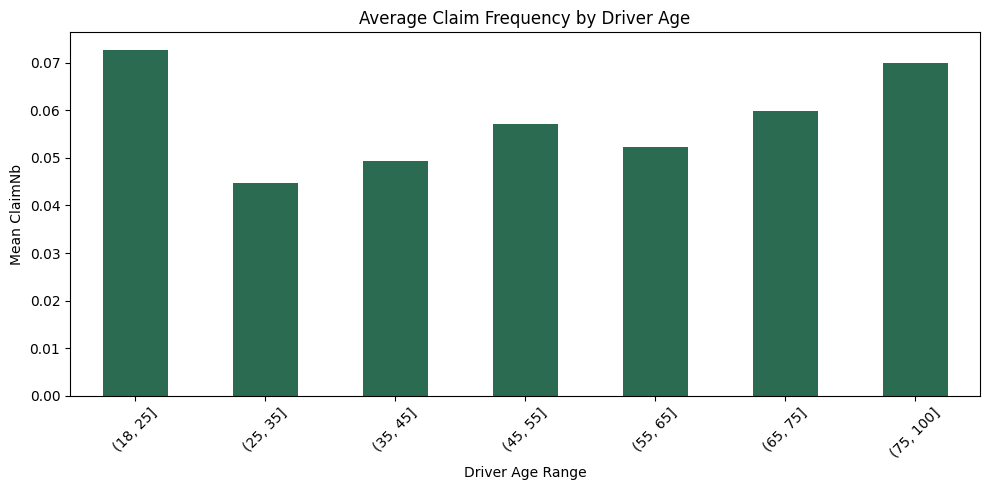

In [33]:
# DrivAge vs claim frequency
age_bins = pd.cut(df_freq['DrivAge'], bins=[18, 25, 35, 45, 55, 65, 75, 100])
df_freq.groupby(age_bins)['ClaimNb'].mean().plot(kind='bar', figsize=(10,5), color='#2a6b52')
plt.title('Average Claim Frequency by Driver Age')
plt.xlabel('Driver Age Range')
plt.ylabel('Mean ClaimNb')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### ClaimNB vs Driver Age shows an expected U- shaped curve, with the highest number of claims and premiums for youngest (18-25) and oldest (75-100) drivers. 

#### Checking records where driver's age is more than 95.

In [34]:
print(df_freq[df_freq['DrivAge'] > 95])

          IDpol  ClaimNb  Exposure Area  VehPower  VehAge  DrivAge  \
7133      20623        1      1.00    A         5       6       99   
7509      21341        1      1.00    E         6       4       99   
8350      22949        1      1.00    D         6       5       99   
8351      22950        1      1.00    D         4       5       99   
12950     31398        0      1.00    C         6      15       99   
...         ...      ...       ...  ...       ...     ...      ...   
580438  4171616        0      1.00    C         4      16       96   
589024  4180202        0      1.00    F         4      14       98   
611786  5040617        0      0.84    C         9       2      100   
611787  5040620        0      0.15    C         9       2      100   
650314  6040618        0      0.74    C         9       3      100   

        BonusMalus VehBrand   VehGas  Density Region  
7133            50       B2   Diesel       26    R24  
7509            50       B5  Regular     9307    

In [35]:
pd.set_option('display.max_rows', None)
print(df_freq[df_freq['DrivAge'] > 95][['IDpol', 'ClaimNb', 'Exposure', 'DrivAge', 'BonusMalus']])
pd.set_option('display.max_rows', 60)  # reset back to default after viewing

          IDpol  ClaimNb  Exposure  DrivAge  BonusMalus
7133      20623        1      1.00       99          50
7509      21341        1      1.00       99          50
8350      22949        1      1.00       99          50
8351      22950        1      1.00       99          50
12950     31398        0      1.00       99          50
14592     34441        0      1.00       99          50
17428     39646        0      1.00       99          50
20283     44813        0      0.87       99          50
20284     44814        0      1.00       99          50
20290     44822        1      0.44       99          50
21604     47223        1      0.50       99          62
22552     48910        0      0.04       99          50
23000     49725        1      1.00       99          58
23070     49858        0      1.00       99          50
23283     50234        0      1.00       99          51
24176     51947        0      1.00       99          57
24259     52094        0      0.33       99     

## Zeroing on Area and Density

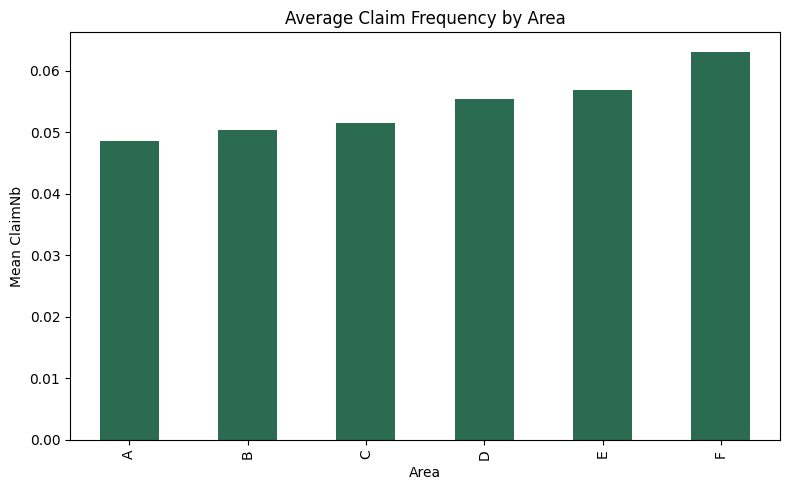

In [36]:
df_freq.groupby('Area')['ClaimNb'].mean().sort_index().plot(kind='bar', figsize=(8,5), color='#2a6b52')
plt.title('Average Claim Frequency by Area')
plt.xlabel('Area')
plt.ylabel('Mean ClaimNb')
plt.tight_layout()
plt.show()

### Does Area actually track Density

In [37]:
df_freq.groupby('Area')['Density'].mean().sort_index()

Area
A       27.503520
B       72.580544
C      248.907258
D     1075.889432
E     4380.239428
F    22015.398226
Name: Density, dtype: float64

### YES!! F denotes more urban - so with an increase in urbanization, the population desnity increases. 

In [38]:
print(df_freq['Region'].value_counts())
print("\nNumber of unique regions:", df_freq['Region'].nunique())

Region
R24    160529
R82     84592
R93     79019
R11     69680
R53     42109
R52     38729
R91     35597
R72     31274
R31     27181
R54     19035
R73     17061
R41     12987
R25     10873
R26     10470
R23      8772
R22      7985
R83      5279
R74      4566
R94      4516
R21      3020
R42      2192
R43      1323
Name: count, dtype: int64

Number of unique regions: 22


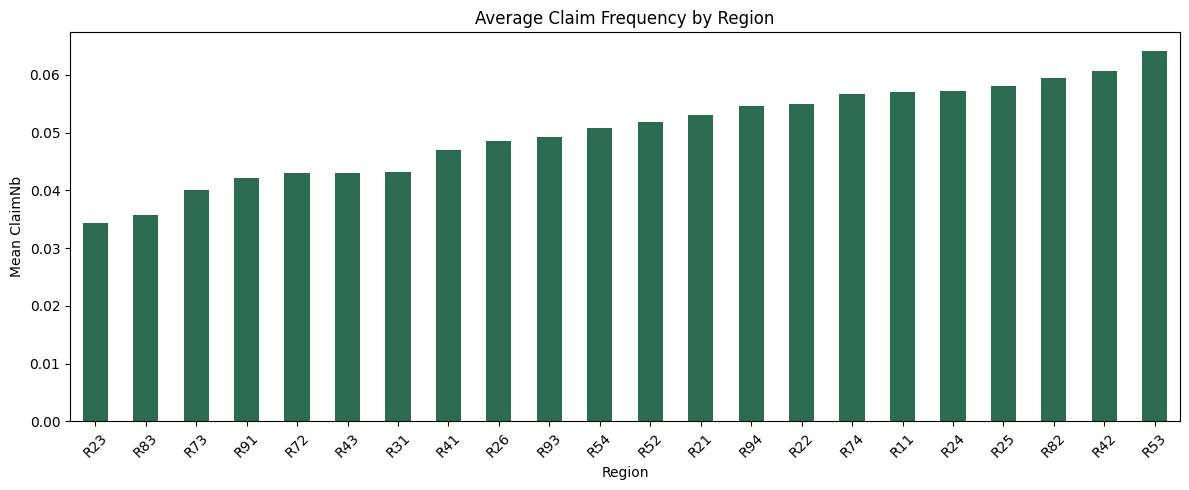

Region
R74     294.162943
R24     460.875941
R54     475.634936
R43     511.539683
R94     534.260407
R26     606.329513
R53     628.802133
R91     649.823553
R25     755.763727
R83     772.653533
R22     886.363306
R21     918.566556
R41     960.052129
R73    1013.898951
R52    1066.590023
R72    1201.878206
R31    1588.553990
R93    1607.986965
R23    1627.437870
R42    1722.390055
R82    2208.923432
R11    8085.072158
Name: Density, dtype: float64


In [39]:
df_freq.groupby('Region')['ClaimNb'].mean().sort_values().plot(kind='bar', figsize=(12,5), color='#2a6b52')
plt.title('Average Claim Frequency by Region')
plt.ylabel('Mean ClaimNb')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df_freq.groupby('Region')['Density'].mean().sort_values())

### Joining frequency and severity data on IDpool

In [40]:
sev_agg = df_sev.groupby('IDpol', as_index=False)['ClaimAmount'].sum()
print("sev_agg shape:", sev_agg.shape)
print(sev_agg.head())

sev_agg shape: (24950, 2)
   IDpol  ClaimAmount
0    139       303.00
1    190      1981.84
2    414      1456.55
3    424     10834.00
4    463      3986.67


In [41]:
df_full = df_freq.merge(sev_agg, on='IDpol', how='left')

# Policies with no claim get NaN for ClaimAmount — fill with 0
df_full['ClaimAmount'] = df_full['ClaimAmount'].fillna(0)

print("df_full shape:", df_full.shape)
print(df_full.head())

df_full shape: (676789, 13)
   IDpol  ClaimNb  Exposure Area  VehPower  VehAge  DrivAge  BonusMalus  \
0      1        1      0.10    D         5       0       55          50   
1      3        1      0.77    D         5       0       55          50   
2      5        1      0.75    B         6       2       52          50   
3     10        1      0.09    B         7       0       46          50   
4     11        1      0.84    B         7       0       46          50   

  VehBrand   VehGas  Density Region  ClaimAmount  
0      B12  Regular     1217    R82          0.0  
1      B12  Regular     1217    R82          0.0  
2      B12   Diesel       54    R22          0.0  
3      B12   Diesel       76    R72          0.0  
4      B12   Diesel       76    R72          0.0  


In [42]:
print("Rows in df_full:", len(df_full))
print("ClaimNb>0 with ClaimAmount=0:", ((df_full['ClaimNb'] > 0) & (df_full['ClaimAmount'] == 0)).sum())
print("ClaimNb>0 with NaN ClaimAmount:", ((df_full['ClaimNb'] > 0) & (df_full['ClaimAmount'].isna())).sum())
print("ClaimNb=0 with ClaimAmount>0:", ((df_full['ClaimNb'] == 0) & (df_full['ClaimAmount'] > 0)).sum())

Rows in df_full: 676789
ClaimNb>0 with ClaimAmount=0: 9116
ClaimNb>0 with NaN ClaimAmount: 0
ClaimNb=0 with ClaimAmount>0: 0


In [43]:
# Confirm: rows with ClaimNb=0 should all have ClaimAmount=0
print(df_full[df_full['ClaimNb'] == 0]['ClaimAmount'].sum())  # should be 0

# Confirm: rows with ClaimNb>0 should mostly have ClaimAmount>0
print((df_full[df_full['ClaimNb'] > 0]['ClaimAmount'] == 0).sum())  # count of claims with $0 amount — investigate if nonzero

0.0
9116


In [44]:
# Check: how many of these 9,116 policies actually appear in sev_agg at all?
claimnb_positive = df_full[df_full['ClaimNb'] > 0]
mismatch = claimnb_positive[claimnb_positive['ClaimAmount'] == 0]

print("Total ClaimNb>0 but ClaimAmount=0:", len(mismatch))
print("Of these, how many IDpol exist in sev_agg:", mismatch['IDpol'].isin(sev_agg['IDpol']).sum())

Total ClaimNb>0 but ClaimAmount=0: 9116
Of these, how many IDpol exist in sev_agg: 0


In [45]:
# 1. Policies with claims but no severity record
missing_severity = df_full[
    (df_full['ClaimNb'] > 0) &
    (df_full['ClaimAmount'].isna())
]

print("ClaimNb > 0 but no severity record:",
      len(missing_severity))


# 2. Policies with claims and severity record, but amount = 0
zero_severity = df_full[
    (df_full['ClaimNb'] > 0) &
    (df_full['ClaimAmount'] == 0)
]

print("ClaimNb > 0 and ClaimAmount = 0:",
      len(zero_severity))


# 3. Number of severity records for these policies
print(
    df_sev[
        df_sev['IDpol'].isin(missing_severity['IDpol'])
    ].shape
)


# 4. Look at actual zero-amount severity records
print(
    df_sev[
        (df_sev['IDpol'].isin(df_full[df_full['ClaimNb'] > 0]['IDpol'])) &
        (df_sev['ClaimAmount'] == 0)
    ].head(20)
)

ClaimNb > 0 but no severity record: 0
ClaimNb > 0 and ClaimAmount = 0: 9116
(0, 2)
Empty DataFrame
Columns: [IDpol, ClaimAmount]
Index: []


In [46]:
mismatch = df_full[(df_full['ClaimNb'] > 0) & (df_full['ClaimAmount'] == 0)]
print(mismatch['ClaimNb'].value_counts())
print(mismatch['Exposure'].describe())

ClaimNb
1    8608
2     485
3      20
4       2
5       1
Name: count, dtype: int64
count    9116.000000
mean        0.505206
std         0.377610
min         0.002732
25%         0.120000
50%         0.460000
75%         1.000000
max         1.000000
Name: Exposure, dtype: float64


In [47]:
mismatch = df_full[(df_full['ClaimNb'] > 0) & (df_full['ClaimAmount'] == 0)]

# Compare distribution to the full claim population
for col in ['Area', 'VehBrand', 'VehGas', 'Region']:
    print(f"\n--- {col} ---")
    print("Mismatch %:")
    print(mismatch[col].value_counts(normalize=True).round(3))
    print("All claims %:")
    print(df_full[df_full['ClaimNb'] > 0][col].value_counts(normalize=True).round(3))


--- Area ---
Mismatch %:
Area
C    0.288
D    0.203
E    0.175
A    0.175
B    0.121
F    0.038
Name: proportion, dtype: float64
All claims %:
Area
C    0.275
D    0.232
E    0.214
A    0.142
B    0.107
F    0.031
Name: proportion, dtype: float64

--- VehBrand ---
Mismatch %:
VehBrand
B12    0.486
B1     0.183
B2     0.180
B3     0.040
B5     0.037
B4     0.022
B6     0.022
B13    0.011
B10    0.009
B11    0.006
B14    0.004
Name: proportion, dtype: float64
All claims %:
VehBrand
B12    0.243
B1     0.240
B2     0.238
B3     0.078
B5     0.056
B6     0.041
B4     0.037
B10    0.024
B11    0.020
B13    0.018
B14    0.005
Name: proportion, dtype: float64

--- VehGas ---
Mismatch %:
VehGas
Regular    0.67
Diesel     0.33
Name: proportion, dtype: float64
All claims %:
VehGas
Regular    0.539
Diesel     0.461
Name: proportion, dtype: float64

--- Region ---
Mismatch %:
Region
R24    0.279
R11    0.145
R93    0.096
R53    0.086
R82    0.083
R91    0.050
R52    0.045
R73    0.033
R72    0.03

In [48]:
# For policies with ClaimAmount > 0, compare average severity by brand
sev_by_brand = df_full[df_full['ClaimAmount'] > 0].groupby('VehBrand')['ClaimAmount'].agg(['mean', 'median', 'count'])
print(sev_by_brand.sort_values('median'))

# Also check average ClaimNb per brand (frequency)
print("\nClaim frequency by brand:")
print(df_full.groupby('VehBrand')['ClaimNb'].mean().sort_values())

                 mean   median  count
VehBrand                             
B6        1648.228467  1128.12   1187
B5        1827.986407  1128.12   1578
B1        2223.003322  1172.00   6499
B10       2302.011740  1172.00    730
B2        2902.791967  1172.00   6467
B14       1756.886429  1172.00    126
B11       3562.173958  1172.00    624
B13       2278.159391  1172.00    509
B4        2419.237158  1172.00   1052
B3        2258.118480  1172.00   2296
B12       2286.727237  1204.00   3825

Claim frequency by brand:
VehBrand
B14    0.040943
B10    0.048526
B6     0.051259
B4     0.052142
B3     0.052754
B11    0.053137
B1     0.053169
B13    0.053182
B12    0.053375
B2     0.053501
B5     0.058169
Name: ClaimNb, dtype: float64


### The missing severity values are mostly evenly distributed across categories, but VehBrand = B12 is a clear, systematic exception. So, severity model will slightly under-estimate average claim size for B12. 

### Since there are 9,116 mismatched rows with ClaimNb > 0 and ClaimAmount = 0, we keep them for frequency modeling, but exclude them from severity modeling. 

## Correlation Heatmap

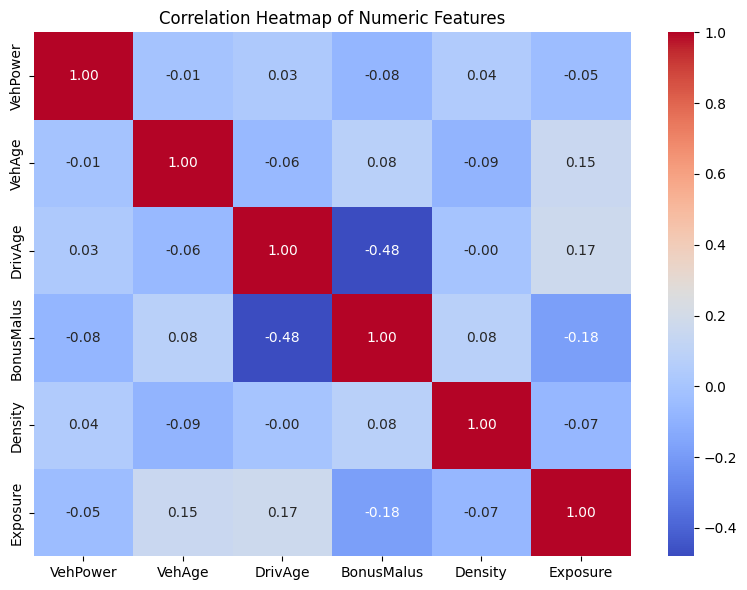

In [49]:
import seaborn as sns

numeric_cols = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Density', 'Exposure']
corr = df_full[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

#### Above, we can see that the correlation between driver's age & Bonus Malus is moderately negatively correlated. Older, more experienced drivers tend to have accumulated more claim-free years, pushing their BonusMalus down. 

In [50]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

numeric_cols = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Density', 'Exposure']
X = df_freq[numeric_cols].dropna()

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)

      feature       VIF
0    VehPower  1.011885
1      VehAge  1.046203
2     DrivAge  1.316416
3  BonusMalus  1.344251
4     Density  1.021445
5    Exposure  1.083013


#### Since VIF between Bonus Malus and Driver's age is less than 5, we keep both features. 